In [1]:
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score

In [2]:
# Добавьте исходный файл в нужную вам папку и укажите путь до его чтения в file_path
file_path = "Леденцы.dat"
data = pd.read_csv(file_path, delimiter=";")

### V1: Я потребляю леденцы, чтобы освежить дыхание

### V2: Я потребляю леденцы, чтобы чувствовать себя увереннее

### V3: Я потребляю леденцы, чтобы освежить полость рта

### V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту

### V5: Я потребляю леденцы как заменитель других кондитерских изделий

### V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого

### V7: Леденцы помогают мне сконцентрироваться

### V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать

### V9: Я потребляю леденцы для того, чтобы облегчить боль в горле

### V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа

### V11: Я потребляю леденцы для улучшения самочувствия

In [3]:
# 11 коллонок с соответствующими вопросами
data

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3
...,...,...,...,...,...,...,...,...,...,...,...
333,3,3,3,3,3,3,5,5,3,3,3
334,3,3,3,3,3,3,5,5,3,3,3
335,3,3,3,3,3,3,5,5,3,3,3
336,3,3,3,3,3,3,5,5,3,3,3


In [4]:
'''
Данные имеют одинаковый диапазон с небольшими отличиями по разбросу и среднему.
'''
'''
Как понимать эти оценки? 
"Я потребляю леденцы, чтобы освежить дыхание - 3". Притом разброс от 2-х до 5-и.
Очень странная формулировка. Можно ли ожидать какой-то перекос?
'''
data.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [5]:
# пропусков в данных нет
data.isna().sum()

V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
dtype: int64

In [6]:
# убедились, что точно нигде нет значений, отличающихся от 2, 3, 4 или 5.
for i in range(1, 12): 
    if Counter(data[f'V{i}'].unique()) != Counter([2, 3, 4 ,5]): 
        print(data[f'V{i}'].unique(), i)

In [7]:
'''
По распределению оценок видно, что большинство поставили тройки. 
Почему редко ставят 2? Не хотят быть такими категоричными?
Почему редко ставят 4? Видят что-то свойственное своим привычкам и сразу ставят 5? 
Получается, в несвойственных себе привычках респонденты не хотят быть категоричными, 
но как дело доходит до своейственных им не стремятся к полумерам. 
'''
all_values = []
for i in data.columns:
    all_values.extend(data[i].tolist())
print(Counter(all_values))

Counter({3: 2336, 5: 844, 2: 323, 4: 215})


In [8]:
alt_columns_names = ['освежить дыхание', 'чувствовать себя увереннее', 'освежить полость рта', 'от неприятного вкуса', 'заменитель кондитерки', 'предовратить/заменить сладкое', 'сконцентрироваться', 'отвлечься', 'облегчить боль в горле', 'от заложенности носа', 'улучшения самочувствия']

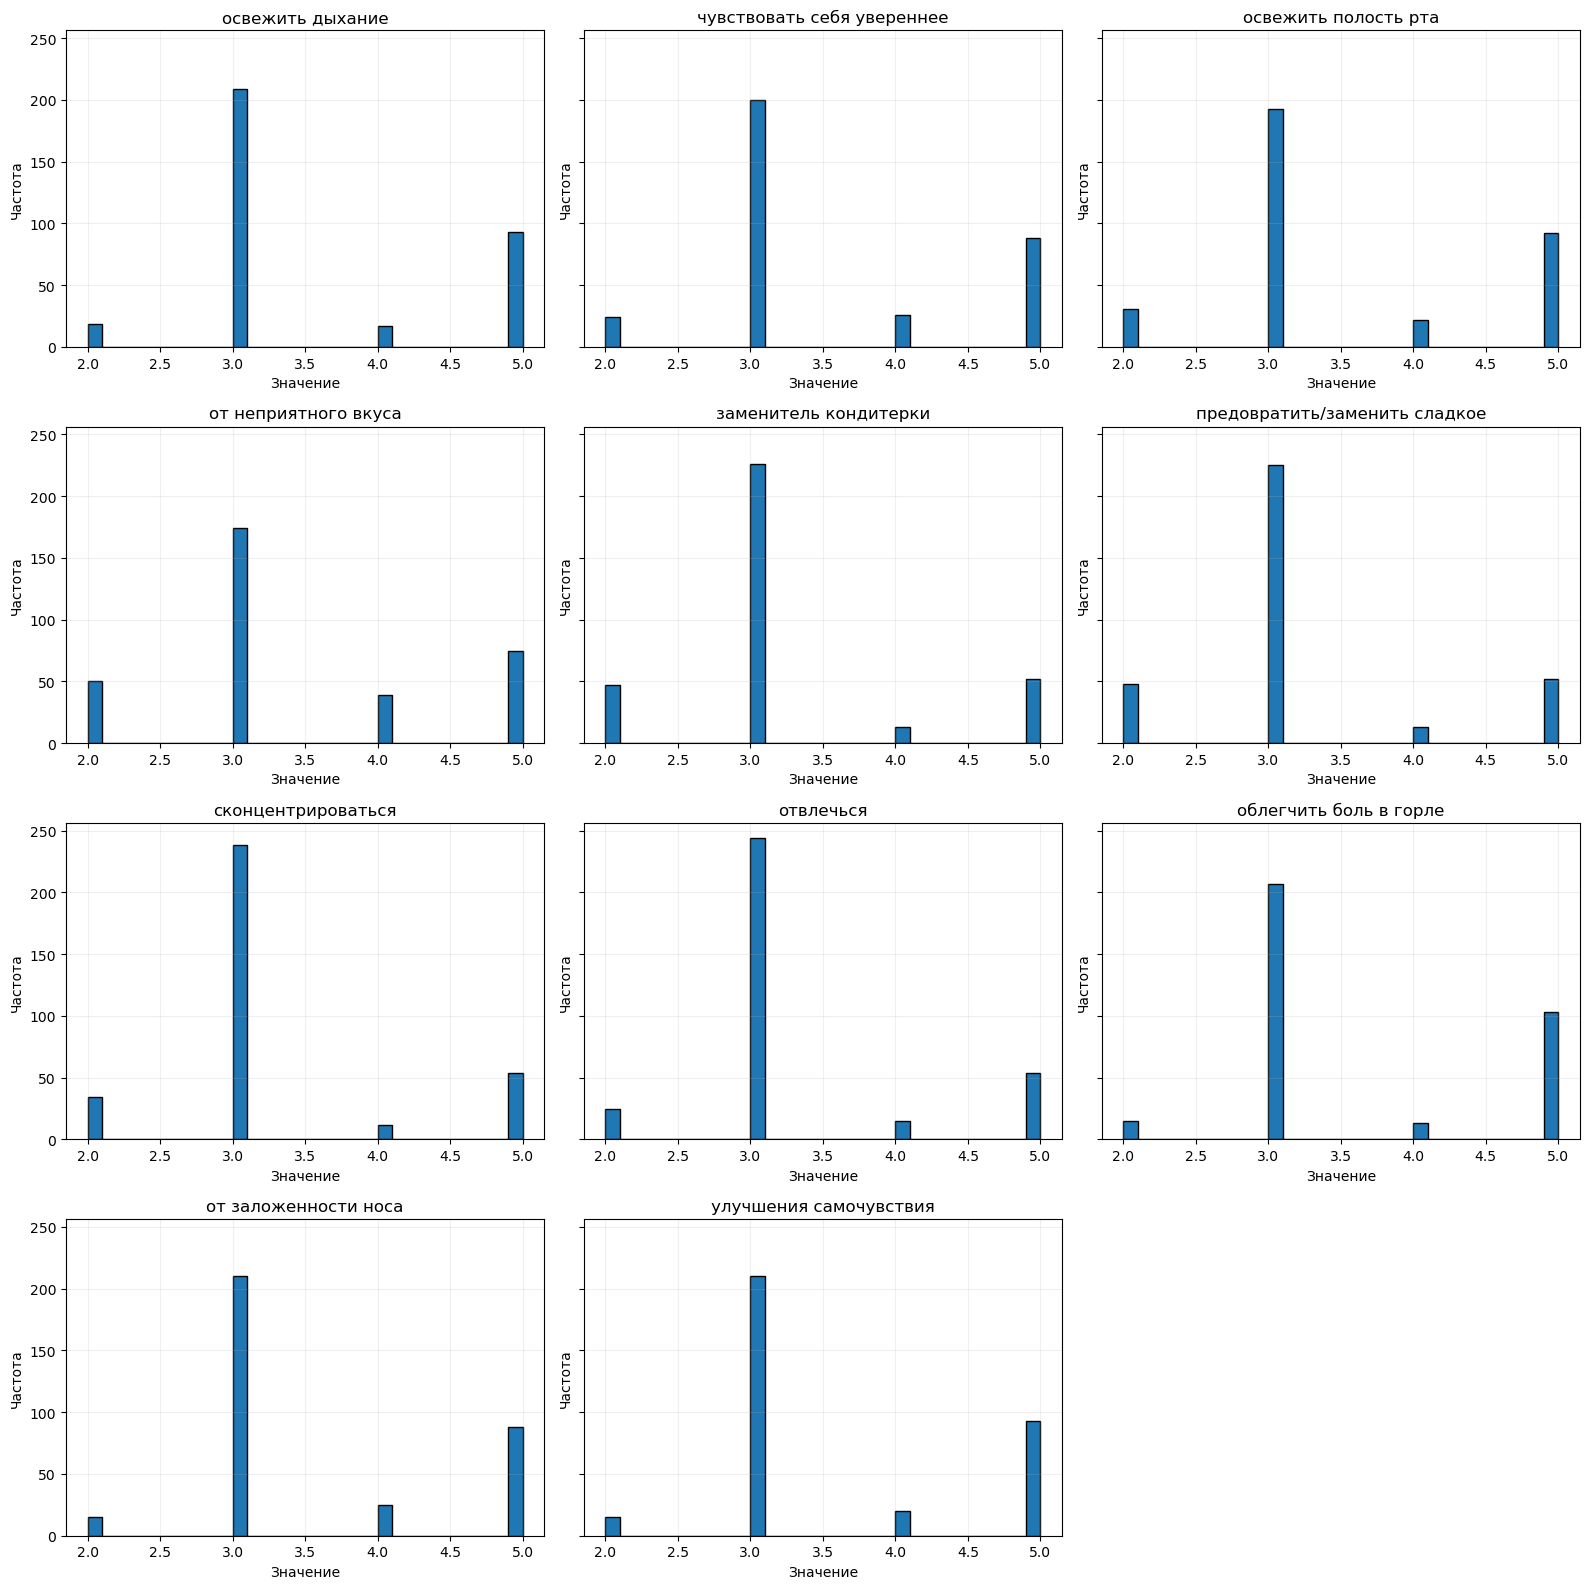

In [9]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16), sharey=True)

col_num = 0
for ax, col in zip(axes.flat, data.columns):
    ax.hist(data[col], bins=30, edgecolor='black')
    ax.set_title(alt_columns_names[col_num])
    ax.set_xlabel('Значение')
    ax.set_ylabel('Частота')
    ax.grid(alpha=0.2)
    col_num += 1

# Убираем лишний 12-й график
for ax in axes.flat[11:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

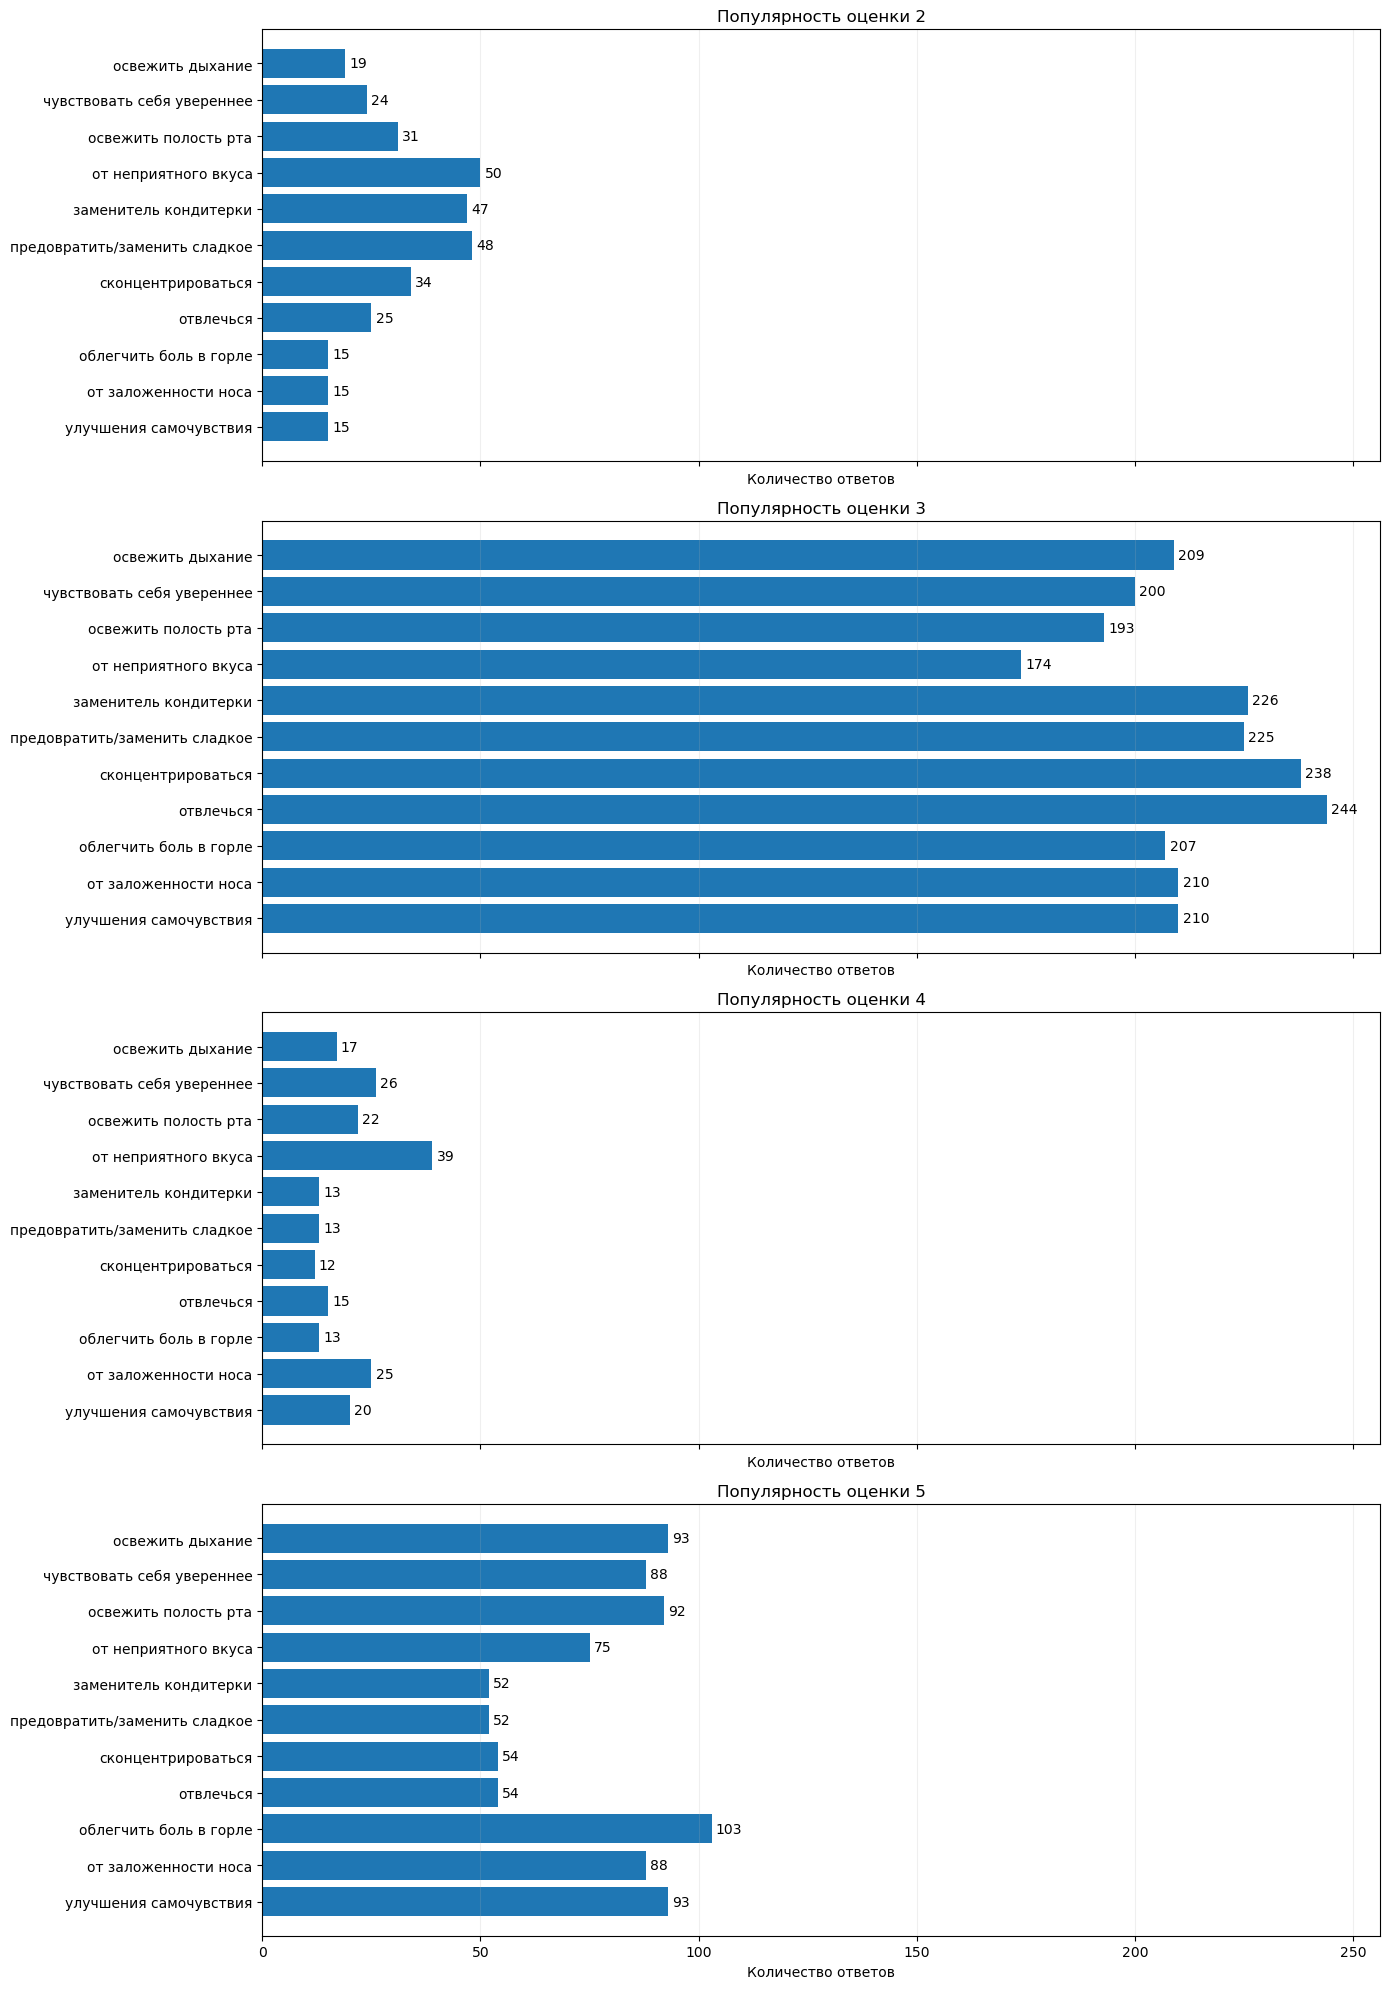

In [10]:
data_renamed = data.copy()
data_renamed.columns = alt_columns_names

ratings = sorted(data_renamed.stack().unique())

fig, axes = plt.subplots(
    len(ratings), 1,
    figsize=(14, 5 * len(ratings)),
    sharex=True
)

for ax, rating in zip(axes, ratings):
    counts = data_renamed.eq(rating).sum()

    bars = ax.barh(counts.index[::-1], counts.values[::-1])

    ax.bar_label(bars, padding=3)
    ax.set_title(f'Популярность оценки {rating}')
    ax.set_xlabel('Количество ответов')
    ax.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.show()

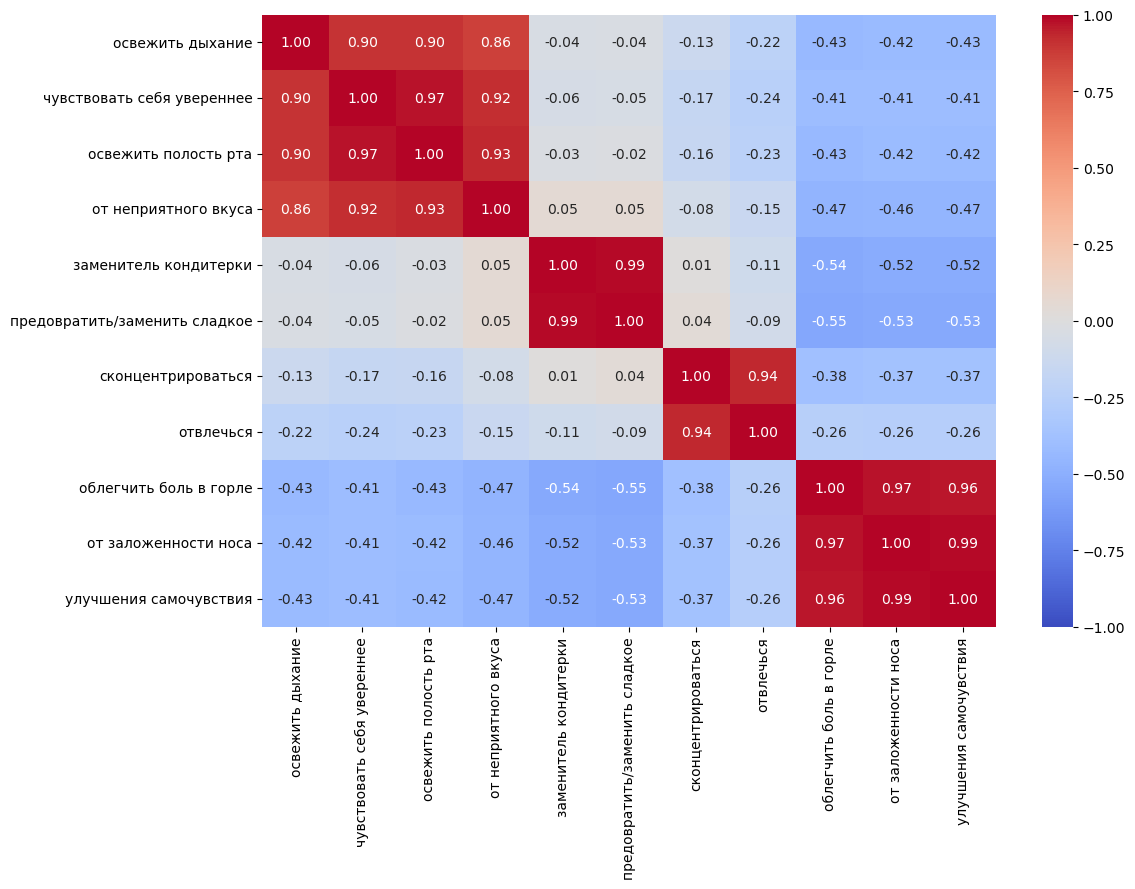

In [11]:
'''
Возможно респонденты очень плохо понимали различие между "заменой кондитерки" и 
подавлением желания съесть что-то сладкое. Не могу даже предположить что под вопросом имелось в виду.
Все сильные корреляции чаще положительные. 
Ну и мы уже можем наблюдать первые потенциальные кластеры - по избавлению от запаха, вкуса и 
добавлению уверенности; по замене кондитерки/сладкого; по улучшению самочувствия.
'''

plt.figure(figsize=(12, 9))
sns.heatmap(
    data_renamed.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)
plt.tight_layout()
plt.show()

In [12]:
# А вот и еще интересная находка - уникальных комбинаций всего 45
# 293 повторяются. То есть нам достаточно 45 сэмплов, чтобы провести кластеризацию.
# Но это их нужно удалить из новой таблицы, сохранить индексы, чтобы потом статистики посчитать... 
print('Уникальных комбинаций:', len(data.drop_duplicates()))
print('Повторяющихся комбинаций:', data.duplicated().sum())

Уникальных комбинаций: 45
Повторяющихся комбинаций: 293


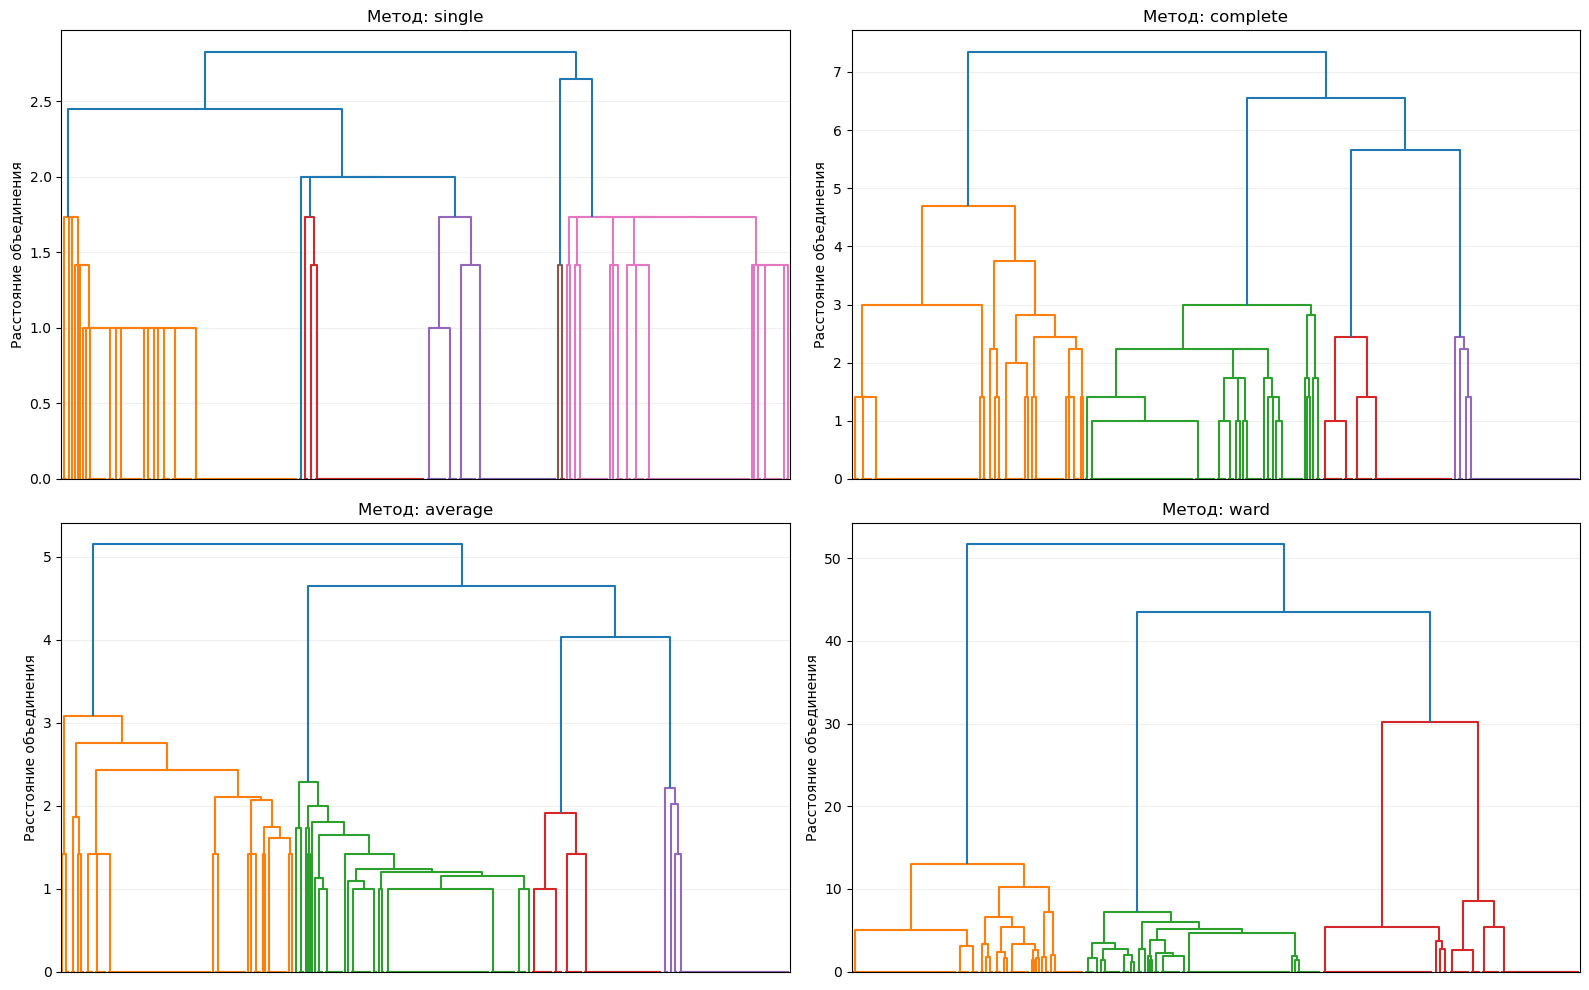

In [13]:
# рас-им 4-е метода просто для наглядности. У Single выделилось 6? кластеров. У complete 4, 
# у average 4, у ward 3. Я скорее согласен с complete и average (а точнее с примененным к ним порогом).
# Пожалуй выделить можно действительно только 4 очевидных класса. 
# Но чтобы не гадать просто посмотрим силуэт-скор
methods = ['single', 'complete', 'average', 'ward']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, method in zip(axes.flat, methods):
    Z = linkage(data_renamed, method=method, metric='euclidean')

    dendrogram(
        Z,
        ax=ax,
        no_labels=True
    )

    ax.set_title(f'Метод: {method}')
    ax.set_ylabel('Расстояние объединения')
    ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

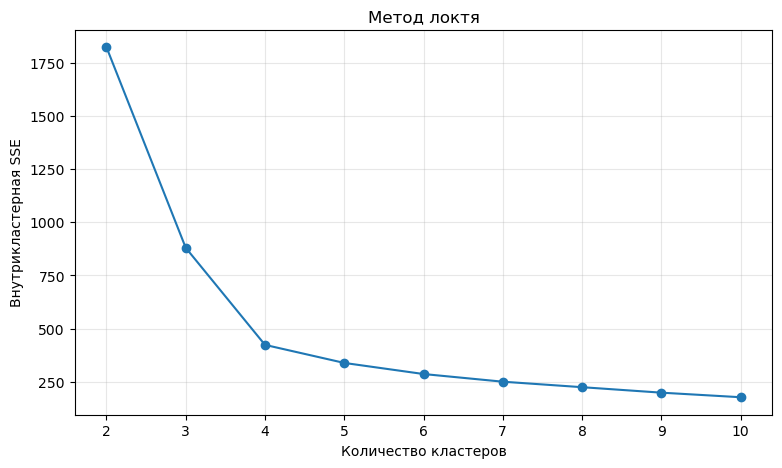

In [19]:
# используем метод локтя. 4 будто бы действительно оптимум
# Но он не учитывает межкластерное расстояние, а считает только компактность внутри одного кластера 
# Посчитаем силуэт-скор, который учтет и межкластерное расстояние

import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import fcluster

X = data_renamed.to_numpy()
ks = range(2, 11)
sse_values = []

for k in ks:
    labels = fcluster(Z, t=k, criterion='maxclust')

    sse = 0
    for cluster in np.unique(labels):
        points = X[labels == cluster]
        centroid = points.mean(axis=0)
        sse += np.sum((points - centroid) ** 2)

    sse_values.append(sse)

plt.figure(figsize=(9, 5))
plt.plot(list(ks), sse_values, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Внутрикластерная SSE')
plt.title('Метод локтя')
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.show()

In [14]:
# силуэт-скор различается значительно. То есть при объединении кластеров он падает

for k in [3, 4]:
    labels = fcluster(Z, t=k, criterion='maxclust')

    score = silhouette_score(data_renamed, labels)

    print(f'{k} кластера: silhouette = {score:.3f}')
    print('Размеры:', pd.Series(labels).value_counts().sort_index().to_dict())
    print()

3 кластера: silhouette = 0.614
Размеры: {1: 108, 2: 110, 3: 120}

4 кластера: silhouette = 0.727
Размеры: {1: 108, 2: 110, 3: 59, 4: 61}



In [17]:
# НО что забавно, самый оптимальный силуэт-скор, если кластеров будет 8
for k in range(2, 11):
    labels = fcluster(Z, t=k, criterion='maxclust')
    score = silhouette_score(data_renamed, labels)
    print(f'{k} кластеров: {score:.3f}')

2 кластеров: 0.455
3 кластеров: 0.614
4 кластеров: 0.727
5 кластеров: 0.698
6 кластеров: 0.729
7 кластеров: 0.731
8 кластеров: 0.744
9 кластеров: 0.645
10 кластеров: 0.659


In [15]:
# эту картинку мы уже видели, когда посмотрели на матрицу коррелляции 
labels = fcluster(Z, t=4, criterion='maxclust')

clustered = data_renamed.copy()
clustered['Кластер'] = labels

cluster_means = clustered.groupby('Кластер').mean().T

display(
    cluster_means.style
    .background_gradient(cmap='YlOrRd', axis=1)
    .format('{:.2f}')
)

Кластер,1,2,3,4
освежить дыхание,2.82,4.85,3.00,3.00
чувствовать себя увереннее,2.83,4.80,2.97,3.00
освежить полость рта,2.77,4.84,2.97,3.00
от неприятного вкуса,2.62,4.68,2.92,3.00
заменитель кондитерки,2.61,3.04,2.92,4.85
предовратить/заменить сладкое,2.58,3.04,2.95,4.85
сконцентрироваться,2.75,3.00,4.92,3.00
отвлечься,2.92,2.99,4.92,2.92
облегчить боль в горле,4.95,3.07,3.00,2.75
от заложенности носа,4.81,3.05,3.00,2.75


In [16]:
# альтернатива - если мы все же возьмем 3 кластера
# тогда увидим, что избегатели сладкого схлопнулись с теми, кто пытается концентрироваться/отвлекаться.
# Может ли быть такое, что у СВДГшников проблемы со сладким....
labels = fcluster(Z, t=3, criterion='maxclust')

clustered = data_renamed.copy()
clustered['Кластер'] = labels

cluster_means = clustered.groupby('Кластер').mean().T

display(
    cluster_means.style
    .background_gradient(cmap='YlOrRd', axis=1)
    .format('{:.2f}')
)

Кластер,1,2,3
освежить дыхание,2.82,4.85,3.00
чувствовать себя увереннее,2.83,4.80,2.98
освежить полость рта,2.77,4.84,2.98
от неприятного вкуса,2.62,4.68,2.96
заменитель кондитерки,2.61,3.04,3.90
предовратить/заменить сладкое,2.58,3.04,3.92
сконцентрироваться,2.75,3.00,3.94
отвлечься,2.92,2.99,3.90
облегчить боль в горле,4.95,3.07,2.88
от заложенности носа,4.81,3.05,2.88


In [18]:
# а вот и 8 кластеров. И в целом у них есть какая-то адекватность
'''
То есть кластер 1-й больше про все виды самочувствия
Кластер 2 больше про боль в горле
Кластер 3 больше про боль в горле и про полость рта и уверенность.
Кластер 4 про все виды самочувствия, но более категоричен относительно многих других и ставит им 2
Кластер 5 про уверенность и полость рта.
Кластер 6 про концентрацию и отвлечение
Кластер 7 про замену сладкого и кодитерки, но категоричный относительно самочувствия и ставит им 2
Кластер 8 тоже про замену сладкого и кондитерки, но менее категоричный относительно самочувствия
'''
labels = fcluster(Z, t=8, criterion='maxclust')

clustered = data_renamed.copy()
clustered['Кластер'] = labels

cluster_means = clustered.groupby('Кластер').mean().T

display(
    cluster_means.style
    .background_gradient(cmap='YlOrRd', axis=1)
    .format('{:.2f}')
)

Кластер,1,2,3,4,5,6,7,8
освежить дыхание,3.00,2.48,2.00,3.00,4.85,3.00,3.00,3.00
чувствовать себя увереннее,3.00,2.24,4.00,3.00,4.80,2.97,3.00,3.00
освежить полость рта,3.00,2.00,4.00,3.00,4.84,2.97,3.00,3.00
от неприятного вкуса,3.00,2.00,4.00,2.00,4.68,2.92,3.00,3.00
заменитель кондитерки,3.00,2.24,2.00,2.00,3.04,2.92,5.00,4.80
предовратить/заменить сладкое,3.00,2.14,2.00,2.00,3.04,2.95,5.00,4.80
сконцентрироваться,3.00,2.76,2.00,2.00,3.00,4.92,3.00,3.00
отвлечься,3.00,3.24,3.00,2.00,2.99,4.92,2.67,3.00
облегчить боль в горле,4.93,4.97,5.00,5.00,3.07,3.00,2.00,3.00
от заложенности носа,4.83,4.72,4.75,4.94,3.05,3.00,2.00,3.00
